# Importing all the required libraties

In [1]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense


c:\Users\Aarya Bhave\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\export\tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


# Loading, Pre-Processing data

In [2]:
df = pd.read_csv('full_german_credit.csv')
df.head()

,Status_of_existing_checking_account,Duration_in_month,Credit_history,Purpose,Credit_amount,Savings_account_bonds,Present_employment_since,Installment_rate_in_percentage_of_disposable_income,Personal_status_and_sex,Other_debtors_guarantors,...,Property,Age_in_years,Other_installment_plans,Housing,Number_of_existing_credits_at_this_bank,Job,Number_of_people_being_liable_to_provide_maintenance_for,Telephone,Foreign_worker,Risk
0,< 0 DM,6,critical account / other credits existing (not...,radio/TV,1169,/ no savings,>= 7 years,4,male: single,NaN,...,real estate,67,NaN,own,2,skilled employee / official,1,"yes, registered under the customers name",yes,good
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,radio/TV,5951,< 100 DM,1 <= ... < 4 years,2,female: divorced/separated/married,NaN,...,real estate,22,NaN,own,1,skilled employee / official,1,NaN,yes,bad
2,no checking account,12,critical account / other credits existing (not...,education,2096,< 100 DM,4 <= ... < 7 years,2,male: single,NaN,...,real estate,49,NaN,own,1,unskilled - resident,2,NaN,yes,good
3,< 0 DM,42,existing credits paid back duly till now,furniture/equipment,7882,< 100 DM,4 <= ... < 7 years,2,male: single,guarantor,...,building society savings agreement / life insu...,45,NaN,for free,1,skilled employee / official,2,NaN,yes,good
4,< 0 DM,24,delay in paying off in the past,car (new),4870,< 100 DM,1 <= ... < 4 years,3,male: single,NaN,...,/ no property,53,NaN,for free,2,skilled employee / official,2,NaN,yes,bad


In [3]:
print(df.info())
print(df.nunique())
print(df.notnull())
print(df.describe())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 21 columns):
 #   Column                                                    Non-Null Count  Dtype 
---  ------                                                    --------------  ----- 
 0   Status_of_existing_checking_account                       1000 non-null   object
 1   Duration_in_month                                         1000 non-null   int64 
 2   Credit_history                                            1000 non-null   object
 3   Purpose                                                   1000 non-null   object
 4   Credit_amount                                             1000 non-null   int64 
 5   Savings_account_bonds                                     1000 non-null   object
 6   Present_employment_since                                  1000 non-null   object
 7   Installment_rate_in_percentage_of_disposable_income       1000 non-null   int64 
 8   Personal_status_and_sex      

In [4]:
df['Telephone'].fillna('unknown', inplace=True)
df['Other_installment_plans'].fillna('unknown', inplace=True)
df['Other_debtors_guarantors'].fillna('unknown', inplace=True)

column = df.columns

le = LabelEncoder()

print((df[column[1]].dtypes))

for cols in column:
    if df[cols].dtypes == "object":
        print("entered")
        df['encoded'+cols] = le.fit_transform(df[cols])

int64
entered
entered
entered
entered
entered
entered
entered
entered
entered
entered
entered
entered
entered
entered


C:\Users\Aarya Bhave\AppData\Local\Temp\ipykernel_29888\859361229.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Telephone'].fillna('unknown', inplace=True)
C:\Users\Aarya Bhave\AppData\Local\Temp\ipykernel_29888\859361229.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

In [5]:
df.head(2)

,Status_of_existing_checking_account,Duration_in_month,Credit_history,Purpose,Credit_amount,Savings_account_bonds,Present_employment_since,Installment_rate_in_percentage_of_disposable_income,Personal_status_and_sex,Other_debtors_guarantors,...,encodedPresent_employment_since,encodedPersonal_status_and_sex,encodedOther_debtors_guarantors,encodedProperty,encodedOther_installment_plans,encodedHousing,encodedJob,encodedTelephone,encodedForeign_worker,encodedRisk
0,< 0 DM,6,critical account / other credits existing (not...,radio/TV,1169,/ no savings,>= 7 years,4,male: single,unknown,...,3,3,2,3,2,1,1,1,1,1
1,0 <= ... < 200 DM,48,existing credits paid back duly till now,radio/TV,5951,< 100 DM,1 <= ... < 4 years,2,female: divorced/separated/married,unknown,...,0,0,2,3,2,1,1,0,1,0


In [6]:
for cols in column:
    if df[cols].dtypes == "object":
        df.drop([cols], axis=1, inplace=True)

# Defining the independent, dependent variables

In [7]:
X = df.drop(['encodedRisk'], axis=1)
y = df['encodedRisk']

# Applying train-test-split

In [8]:
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=3, shuffle=True, test_size=0.2)

# Building the network

In [9]:
model = Sequential()

model.add(Dense(16, input_dim = X_train.shape[1], activation = 'relu'))
model.add(Dense(10, activation = 'relu'))
model.add(Dense(1, activation='sigmoid'))

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

c:\Users\Aarya Bhave\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\core\dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


# Training the model

In [10]:
train = model.fit(X_train, y_train, epochs=50, batch_size=16, validation_split=0.2)

Epoch 1/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - accuracy: 0.4859 - loss: 122.5636 - val_accuracy: 0.6313 - val_loss: 3.1989
Epoch 2/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6344 - loss: 5.9573 - val_accuracy: 0.6000 - val_loss: 1.9857
Epoch 3/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7016 - loss: 1.8943 - val_accuracy: 0.5938 - val_loss: 2.7038
Epoch 4/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6438 - loss: 3.6687 - val_accuracy: 0.6250 - val_loss: 1.6269
Epoch 5/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6641 - loss: 2.1952 - val_accuracy: 0.6250 - val_loss: 1.3691
Epoch 6/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6484 - loss: 2.2962 - val_accuracy: 0.5938 - val_loss: 2.1287
Epoch 7/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6484 - loss: 2.6889 - val_accuracy: 0.5938 - val_loss: 2.3036
Epoch 8/50
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6656 - loss: 1.7060 - val_accuracy: 0.6125 - val_los

# Calculating the accuracy

In [11]:
loss, accuracy = model.evaluate(X_test, y_test)
y_predict = model.predict(X_test)

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6950 - loss: 1.6450  
7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step 


In [12]:
print("Accuracy : ",accuracy)

Accuracy :  0.6949999928474426


Text(0.5, 1.0, 'Accuracy')

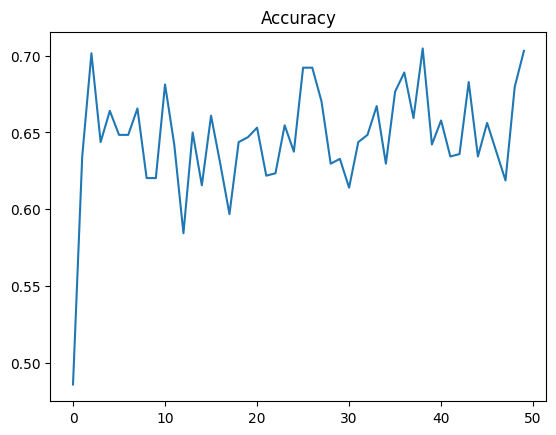

In [15]:
import matplotlib.pyplot as plt

plt.plot(train.history['accuracy'])
plt.title('Accuracy')

Text(0.5, 1.0, 'Loss')

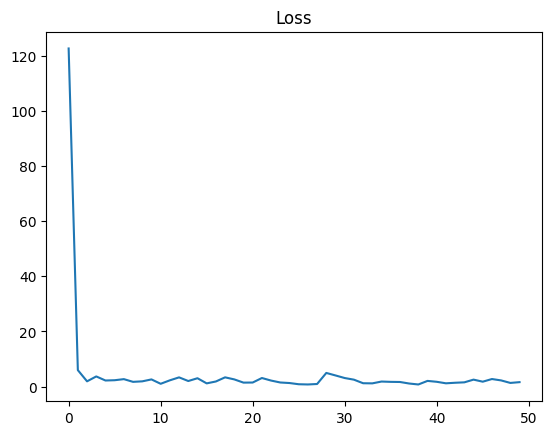

In [17]:
plt.plot(train.history['loss'])
plt.title('Loss')